# Practical 4: Data Visualization

**Dataset:** TeachingRatings.csv

**Aim:** Compare all records with unique instructors and visualize evaluation scores using bar charts and scatter plots.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

ratings = pd.read_csv("TeachingRatings.csv")
unique_prof = ratings.drop_duplicates(subset="prof")
print(ratings.shape, unique_prof.shape)

(463, 13) (94, 13)


**Result:** The table has 463 records but only 94 different instructors, because each instructor teaches several courses.

In [2]:
age_compare = pd.DataFrame({
    "All records": ratings["age"].agg(["count", "mean", "std"]),
    "Unique instructors": unique_prof["age"].agg(["count", "mean", "std"]),
}).round(2)
age_compare

       All records  Unique instructors
count       463.00               94.00
mean         48.37               47.55
std           9.80               10.26

**Result:** Mean age is 48.37 for all records and 47.55 for unique instructors. Standard deviation is 9.8 and 10.26. The values are close, so repeated records do not change the age picture much.

division
lower    4.087
upper    3.953
Name: eval, dtype: float64


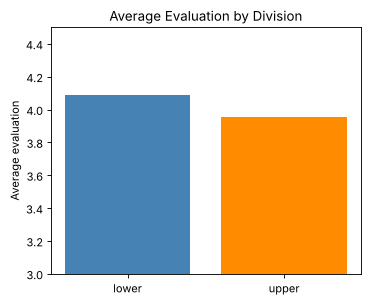

In [3]:
division_mean = ratings.groupby("division")["eval"].mean().round(3)
print(division_mean)
plt.figure(figsize=(5, 4))
plt.bar(division_mean.index, division_mean.values, color=["steelblue", "darkorange"])
plt.ylim(3, 4.5)
plt.title("Average Evaluation by Division")
plt.ylabel("Average evaluation")
plt.show()

**Result:** Lower division courses average 4.087 and upper division courses average 3.953. Instructors of lower division courses are rated slightly higher.

Correlation: -0.052


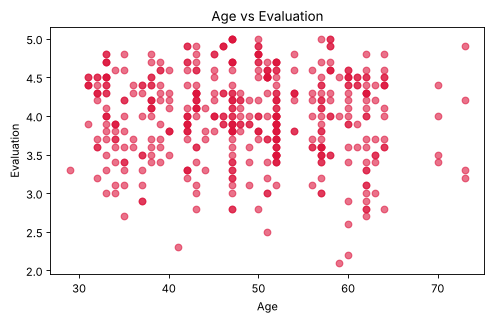

In [4]:
plt.figure(figsize=(7, 4))
plt.scatter(ratings["age"], ratings["eval"], color="crimson", alpha=0.6)
plt.title("Age vs Evaluation")
plt.xlabel("Age")
plt.ylabel("Evaluation")
plt.show()
age_corr = round(ratings["age"].corr(ratings["eval"]), 3)
print("Correlation:", age_corr)

**Result:** The points are widely scattered and the correlation is -0.052, so age has almost no linear relationship with evaluation scores.

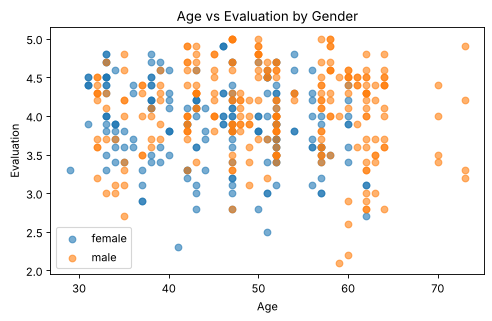

In [5]:
plt.figure(figsize=(7, 4))
for name, part in ratings.groupby("gender"):
    plt.scatter(part["age"], part["eval"], alpha=0.6, label=name)
plt.title("Age vs Evaluation by Gender")
plt.xlabel("Age")
plt.ylabel("Evaluation")
plt.legend()
plt.show()

**Result:** Male and female instructors show a similar scattered pattern. Gender does not create a clear age effect.

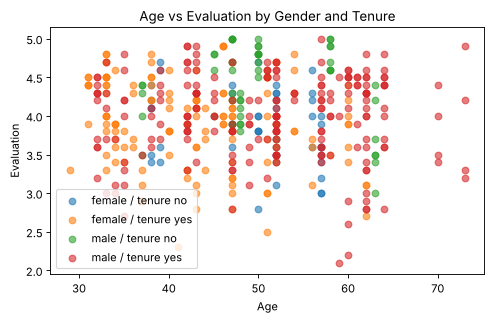

In [6]:
plt.figure(figsize=(7, 4))
for (g, t), part in ratings.groupby(["gender", "tenure"]):
    plt.scatter(part["age"], part["eval"], alpha=0.6, label=g + " / tenure " + t)
plt.title("Age vs Evaluation by Gender and Tenure")
plt.xlabel("Age")
plt.ylabel("Evaluation")
plt.legend()
plt.show()

**Result:** The four groups overlap heavily and evaluation scores stay in the same range in every group, so age is a weak predictor of evaluation.